# Confirmation test · C3/C4 alpha and reported heat pain

**Hypothesis.** Within a person at the same programmed heat level and similar measured temperature, the change in reported pain between repeats is associated with the change in locally referenced C3/C4 alpha power (8–13 Hz), after accounting for temperature differences and the shared repeat pattern.

The protocol and participant IDs were locked in **c3-c4-alpha-analysis-lock.json** before downloading the 59 confirmation recordings. The 15 pilot participants are excluded. The source is [OpenNeuro ds008349 v2.0.1](https://openneuro.org/datasets/ds008349/versions/2.0.1). This is one two-sided confirmation test.

In [1]:
from hashlib import sha256
from itertools import combinations
import json
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy import signal

lock_path = Path("c3-c4-alpha-analysis-lock.json")
lock_bytes = lock_path.read_bytes()
assert sha256(lock_bytes).hexdigest() == "37716ce8fc908cfe245b3426d9f6d2aff4ad54bba9fe5da3a6432a5e54c40eee"
plan = json.loads(lock_bytes)
subjects = plan["confirmation_participants"]
assert len(subjects) == 59 and not set(subjects) & set(plan["pilot_participants_excluded"])

root = Path("data/raw/ds008349-2.0.1")
manifest = json.loads((root / "confirmation-heat-download-manifest.json").read_text())
assert manifest["version"] == "2.0.1"
assert sorted(f"sub-{s}" for s in manifest["subjects"]) == subjects
assert manifest["tree_sha"] == "3252827891885aa1890e6b1531a2d3aeefeaa5fd"
for file in manifest["files"]:
    assert (root / file["path"]).stat().st_size == file["bytes"], file["path"]

fs = plan["expected_structure"]["sfreq_hz"]
levels = plan["expected_structure"]["levels"]
screen = plan["screen"]
eeg_floor, eeg_ceiling = screen["eeg_peak_to_peak_microvolts_inclusive"]
eye_names = screen["eog_channels"]
neighbors = plan["alpha"]["local_reference"]
protected = {"Cz", *neighbors, *(ch for names in neighbors.values() for ch in names)}
primary_eye_threshold = screen["primary_eog_peak_to_peak_microvolts_exclusive"]
minimum_common = screen["min_common_passing_seconds"]
eye_filter = signal.butter(3, screen["eog_filter_hz"], fs=fs, btype="bandpass", output="sos")
repeat_by_block = [levels[:i + 1].count(level) for i, level in enumerate(levels)]
print(f"Locked {plan['locked_utc']}. Verified manifest for {len(subjects)} recordings.")

Locked 2026-11-22T07:16:28+00:00. Verified manifest for 59 recordings.


## Apply the locked screen before making pairs

Use 15–25 seconds to nominate at most two failing scalp electrodes per person. Protect the central electrodes and their reference neighbors. Analyze seconds 25–35 only. For each second, the retained scalp channels must stay within 0.5–150 µV peak to peak. Both recorded eye leads, filtered at 1–10 Hz, must be below 100 µV peak to peak. The rating span must be at most one released unit.

For local alpha, subtract the fixed four-neighbor mean from C3 and C4 separately. Sum the 8–13 Hz bins of the constant-detrended, one-second Hann periodogram, take the log at each site, and average the two log values. Ratings are compared only once the recording structure, labels, and matched seconds have passed their checks.

In [2]:
class RecordingStructureError(ValueError):
    # A recording lacks the structure required by the locked analysis.
    pass


def require(condition, reason):
    if not condition:
        raise RecordingStructureError(reason)


def eeg_failures(eeg_data):
    amplitude = np.ptp(eeg_data, axis=-1) * 1e6
    return ~np.isfinite(amplitude) | (amplitude < eeg_floor) | (amplitude > eeg_ceiling)


def extract_recording(subject):
    prefix = root / subject / "eeg" / f"{subject}_task-thermalactive"
    channel_table = pd.read_csv(f"{prefix}_channels.tsv", sep="\t")
    eeg = channel_table.loc[channel_table["type"].eq("EEG"), "name"].tolist()
    eog = channel_table.loc[channel_table["type"].eq("EOG"), "name"].tolist()
    misc = channel_table.loc[~channel_table["type"].isin(["EEG", "EOG"]), "name"].tolist()
    channels = eeg + eye_names + ["stim", "thermode", "rating"]
    reference = json.loads(Path(f"{prefix}_eeg.json").read_text())["EEGReference"]
    require(len(eeg) == 63 and reference == "FCz" and protected.issubset(eeg)
            and set(eye_names).issubset(eog), "Missing required montage, eye leads, or FCz reference")

    raw = mne.io.read_raw_brainvision(f"{prefix}_eeg.vhdr", eog=eog, misc=misc,
                                     preload=False, ignore_marker_types=True, verbose="ERROR")
    require(raw.info["sfreq"] == fs and set(channels).issubset(raw.ch_names),
            "Unexpected recording rate or missing required signal")
    events = pd.read_csv(f"{prefix}_events.tsv", sep="\t")
    labels = events["trial_type"].tolist()
    expected = [f"t{i:02d}/p{level}" for i, level in enumerate(levels, 1)] + ["t10/end"]
    require(labels == expected, "Unexpected heat block labels or order")
    require(labels == raw.annotations.description.tolist(), "BrainVision and event table labels disagree")
    event_samples = events["sample"].to_numpy(dtype=int)
    max_sample_error = np.abs(np.rint(events["onset"].to_numpy() * fs) - event_samples).max()
    max_marker_error = 1e3 * np.abs(events["onset"].to_numpy() - raw.annotations.onset).max()
    require(max_sample_error <= 1 and max_marker_error <= 1 + 1e-6,
            f"Event clocks disagree beyond 1 ms ({max_sample_error:g} samples; {max_marker_error:.3f} ms)")
    require((event_samples >= 0).all() and (event_samples < raw.n_times).all()
            and (np.diff(event_samples) >= fs * 38).all(),
            "Event locations cannot support the locked analysis intervals")

    # Rating log alignment is checked separately from the embedded rating screen.
    log = pd.read_csv(f"{prefix}_stim.tsv.gz", sep="\t")
    log_times = log["times (s)"].to_numpy()
    in_range = np.isfinite(log_times) & (log_times >= 0) & (log_times <= (raw.n_times - 1) / fs)
    log_samples = np.rint(log_times[in_range] * fs).astype(int)
    embedded = raw.get_data(picks=["rating"])[0][log_samples]
    log_agreement = np.isclose(embedded, log.loc[in_range, "rating"], rtol=0, atol=1e-6).sum()

    calibrate = slice(3 * fs, 13 * fs)  # event seconds 15–25 within 12–38
    analyze = slice(13 * fs, 23 * fs)   # event seconds 25–35 within 12–38
    failure_counts = np.zeros(len(eeg), dtype=int)
    segments = []
    for index, (level, sample) in enumerate(zip(levels, event_samples)):
        data = raw.get_data(picks=channels, start=sample + 12 * fs, stop=sample + 38 * fs)
        scalp = data[:len(eeg)]
        failure_counts += eeg_failures(scalp[:, calibrate].reshape(len(eeg), 10, fs)).sum(axis=1)
        failed = eeg_failures(scalp[:, analyze].reshape(len(eeg), 10, fs))

        eye_slow = signal.sosfiltfilt(eye_filter, data[len(eeg):len(eeg) + 2], axis=1)
        eye_amplitude = np.ptp(eye_slow[:, analyze].reshape(2, 10, fs), axis=-1).max(axis=0) * 1e6
        retain_alpha_sites = np.stack([
            scalp[eeg.index(center), analyze] - scalp[[eeg.index(ch) for ch in adjacent], analyze].mean(axis=0)
            for center, adjacent in neighbors.items()
        ])
        frequencies, psd = signal.periodogram(retain_alpha_sites.reshape(2, 10, fs),
                                               fs=fs, window="hann", axis=-1, detrend="constant")
        lo, hi = plan["alpha"]["frequency_bins_hz_inclusive"]
        band = (frequencies >= lo) & (frequencies <= hi)
        with np.errstate(divide="ignore", invalid="ignore"):
            alpha = np.log(psd[:, :, band].sum(axis=-1)).mean(axis=0)
        stimulus, temp, rating = data[-3:, analyze].reshape(3, 10, fs)
        valid = (
            (np.isfinite(stimulus) & np.isclose(stimulus, level)).all(axis=1)
            & (np.isfinite(temp) & (temp > 0)).all(axis=1)
            & (np.isfinite(rating) & (rating >= 0) & (rating != 999)).all(axis=1)
        )
        rating_steady = np.ptp(rating, axis=-1) <= screen["max_rating_span_per_second_inclusive"]
        segments.append({
            "Subject": subject, "Block": index + 1, "Level": level, "Repeat": repeat_by_block[index],
            "Failed EEG": failed, "Eye swing": eye_amplitude, "Log alpha": alpha,
            "Temperature": np.median(temp, axis=1), "Rating": np.median(rating, axis=1),
            "Valid labels": valid, "Steady rating": rating_steady,
        })

    ranked = sorted(
        (i for i, name in enumerate(eeg) if name not in protected and failure_counts[i] > 0),
        key=lambda i: (-failure_counts[i], eeg[i]),
    )
    omitted = ranked[:screen["omit_up_to_n_scalp_channels"]]
    included = np.ones(len(eeg), dtype=bool)
    included[omitted] = False
    for segment in segments:
        segment["Pass before eye screen"] = (
            ~segment.pop("Failed EEG")[included].any(axis=0)
            & segment["Valid labels"] & segment["Steady rating"]
            & np.isfinite(segment["Eye swing"]) & np.isfinite(segment["Log alpha"])
        )
    return segments, {
        "Recording": subject, "Structurally valid": True, "Reason": "",
        "Omitted channels": ", ".join(eeg[i] for i in omitted),
        "Rating log rows": len(log), "Rating log matches": int(log_agreement),
    }


recordings, quality_rows = {}, []
for subject in subjects:
    try:
        recordings[subject], quality = extract_recording(subject)
    except RecordingStructureError as error:
        quality = {"Recording": subject, "Structurally valid": False, "Reason": str(error)}
    quality_rows.append(quality)

quality = pd.DataFrame(quality_rows)
print(f"{len(recordings)} of {len(subjects)} recordings met the structural checks.")
print(f"Separate rating log agreed on {quality['Rating log matches'].sum():,.0f} "
      f"of {quality['Rating log rows'].sum():,.0f} checked rows.")

59 of 59 recordings met the structural checks.
Separate rating log agreed on 1,475,000 of 1,475,000 checked rows.


## Construct matched repeat comparisons

Compare the same relative seconds in two repeats at the same programmed heat level. Keep a second if both recordings of that interval pass the screen and their measured temperatures differ by at most 0.10°C. A pair needs at least five such seconds. For each block use the median of the second-level ratings and temperatures, and the mean of the second-level log power. Subtract the earlier block from the later one. Some comparisons share a block.

In [3]:
def build_pairs(recordings, eye_threshold):
    pairs, retention = [], []
    for subject, blocks in recordings.items():
        passed = {
            block["Block"]: block["Pass before eye screen"] & (block["Eye swing"] < eye_threshold)
            for block in blocks
        }
        before_count = len(pairs)
        for level in sorted(set(levels)):
            same_level = [block for block in blocks if block["Level"] == level]
            for earlier, later in combinations(same_level, 2):
                temperature_gap = np.abs(later["Temperature"] - earlier["Temperature"])
                matched = (
                    passed[earlier["Block"]] & passed[later["Block"]]
                    & (temperature_gap <= screen["temperature_tolerance_celsius_inclusive"] + 1e-9)
                )
                if matched.sum() < minimum_common:
                    continue
                pairs.append({
                    "Participant": subject, "Level": level,
                    "Repeat contrast": f"{level}:{earlier['Repeat']}-{later['Repeat']}",
                    "Earlier block": earlier["Block"], "Later block": later["Block"],
                    "Matched seconds": int(matched.sum()),
                    "Rating change": np.median(later["Rating"][matched]) - np.median(earlier["Rating"][matched]),
                    "Temperature change": np.median(later["Temperature"][matched]) - np.median(earlier["Temperature"][matched]),
                    "Log alpha change": np.mean(later["Log alpha"][matched] - earlier["Log alpha"][matched]),
                    "Slow EOG change": np.mean(later["Eye swing"][matched] - earlier["Eye swing"][matched]),
                })
        retention.append({
            "Recording": subject, "Seconds passed": int(sum(x.sum() for x in passed.values())),
            "Blocks with at least five seconds": int(sum(x.sum() >= minimum_common for x in passed.values())),
            "Matched pairs": len(pairs) - before_count,
        })
    return pd.DataFrame(pairs), pd.DataFrame(retention)


pairs, retention = build_pairs(recordings, primary_eye_threshold)
flow = quality.merge(retention, on="Recording", how="left", validate="one_to_one")
flow_columns = ["Seconds passed", "Blocks with at least five seconds", "Matched pairs"]
flow[flow_columns] = flow[flow_columns].fillna(0).astype(int)
flow["Outcome"] = np.select(
    [~flow["Structurally valid"], flow["Matched pairs"].gt(0),
     flow["Blocks with at least five seconds"].eq(0)],
    ["Structural exclusion", "Contributed to test", "No block with five passing seconds"],
    default="Passing block, no matched pair",
)
counts = flow["Outcome"].value_counts()
assert counts.sum() == 59 and flow["Matched pairs"].sum() == len(pairs)
print(f"{len(manifest['subjects'])} verified downloads.")
print(f"{len(recordings)} structurally valid.")
print(f"{flow['Blocks with at least five seconds'].gt(0).sum()} had a block with at least five passing seconds.")
print(f"{pairs['Participant'].nunique()} contributed {len(pairs)} matched pairs to the primary test.")
display(counts.rename("Recordings").to_frame())
display(flow[["Recording", "Outcome", "Reason", "Omitted channels", *flow_columns]])

59 verified downloads.
59 structurally valid.
44 had a block with at least five passing seconds.
31 contributed 140 matched pairs to the primary test.


,Recordings
Outcome,
Contributed to test,31
No block with five passing seconds,15
"Passing block, no matched pair",13


,Recording,Outcome,Reason,Omitted channels,Seconds passed,Blocks with at least five seconds,Matched pairs
0,sub-056,No block with five passing seconds,,"Fp1, T7",4,0,0
1,sub-057,"Passing block, no matched pair",,"Fp2, AF7",28,2,0
2,sub-059,Contributed to test,,"Fp1, AF7",45,5,1
3,sub-060,"Passing block, no matched pair",,"Fp2, Fp1",25,2,0
4,sub-064,"Passing block, no matched pair",,"AF7, Fp1",18,1,0
5,sub-066,Contributed to test,,"F6, T7",30,4,1
6,sub-067,Contributed to test,,"Fp2, Fp1",51,6,2
7,sub-068,No block with five passing seconds,,"AF8, AF7",8,0,0
8,sub-069,No block with five passing seconds,,"T8, TP7",11,0,0
9,sub-070,"Passing block, no matched pair",,"AF3, O2",31,3,0


## Estimate the association and its uncertainty

The slope is the expected change in natural-log alpha for a **10-unit difference in rating change**, after adjustment for the temperature difference and level-specific repeat contrast. Each participant gets the same total weight. The model projects both alpha and rating changes off the nuisance variables, then relates the remaining differences.

Resample participants, carrying all their comparisons together, for the two-sided bootstrap test and 95% interval. This keeps the dependence between pairs from the same recording. The percent change is 100 × (exp(slope) − 1). A positive slope points toward higher alpha with higher ratings. The 75 and 150 µV eye thresholds and residual slow-eye adjustment are prespecified sensitivity checks.

In [4]:
def fit_association(data, adjust_eye=False):
    outcome = data["Log alpha change"].to_numpy(dtype=float)
    rating = data["Rating change"].to_numpy(dtype=float) / 10
    order = pd.get_dummies(data["Repeat contrast"]).to_numpy(dtype=float)
    nuisance_terms = [order, data["Temperature change"].to_numpy() / 0.1]
    if adjust_eye:
        nuisance_terms.append(data["Slow EOG change"].to_numpy() / 100)
    nuisance = np.column_stack(nuisance_terms)
    participant_code, participant_ids = pd.factorize(data["Participant"], sort=True)
    n_participants = len(participant_ids)
    n_pairs_for_person = np.bincount(participant_code)[participant_code]
    require(n_participants >= 2, "Too few contributing participants for a cluster bootstrap")

    def estimate(cluster_multiplicities):
        # Repeated draw counts represent copies of the whole participant.
        weights = np.sqrt(cluster_multiplicities[participant_code] / n_pairs_for_person)
        design = nuisance * weights[:, None]
        values = np.column_stack([rating, outcome]) * weights[:, None]
        fitted = design @ np.linalg.lstsq(design, values, rcond=None)[0]
        rating_residual, alpha_residual = (values - fitted).T
        variation = rating_residual @ rating_residual
        if variation <= 1e-12 * max(1.0, values[:, 0] @ values[:, 0]):
            return np.nan
        return float((rating_residual @ alpha_residual) / variation)

    beta = estimate(np.ones(n_participants, dtype=int))
    require(np.isfinite(beta), "The rating coefficient is unidentified after nuisance adjustment")
    rng = np.random.default_rng(plan["inference"]["seed"])
    attempts = plan["inference"]["bootstrap_attempts"]
    multiplicities = rng.multinomial(n_participants, np.full(n_participants, 1 / n_participants), size=attempts)
    estimates = np.array([estimate(draw) for draw in multiplicities])
    errors = estimates[np.isfinite(estimates)] - beta
    require(len(errors) > 0, "The bootstrap produced no identifiable rating coefficients")
    limits = beta - np.quantile(errors, [0.975, 0.025])
    smaller_tail = min((errors <= beta).sum(), (errors >= beta).sum())
    p = min(1.0, 2 * (smaller_tail + 1) / (len(errors) + 1))
    effect_percent, *percent_limits = 100 * np.expm1([beta, *limits])
    return {
        "Participants": n_participants, "Pairs": len(data), "Log effect": float(beta),
        "Log CI low": float(limits[0]), "Log CI high": float(limits[1]),
        "Percent effect": float(effect_percent),
        "Percent CI low": float(percent_limits[0]), "Percent CI high": float(percent_limits[1]),
        "Two-sided p": float(p), "Valid bootstrap draws": int(len(errors)),
    }


analyses = [
    ("Primary · 100 µV eye limit", pairs, False),
    ("75 µV eye limit", build_pairs(recordings, 75)[0], False),
    ("150 µV eye limit", build_pairs(recordings, 150)[0], False),
    ("100 µV + residual eye covariate", pairs, True),
]
result_rows = []
for name, data, adjust_eye in analyses:
    result = fit_association(data, adjust_eye)
    result_rows.append({"Analysis": name, **result})
results = pd.DataFrame(result_rows)
primary_result = result_rows[0]
primary_coverage = {
    "Downloaded": len(manifest["subjects"]), "Structurally valid": len(recordings),
    "Has passing block": int(flow["Blocks with at least five seconds"].gt(0).sum()),
    "Contributes": int(pairs["Participant"].nunique()),
    "Pairs": len(pairs), "Matched pair-seconds": int(pairs["Matched seconds"].sum()),
}
print(f"Primary effect: {primary_result['Log effect']:+.5f} log units "
      f"({primary_result['Percent effect']:+.2f}% per 10 rating units).")
print(f"Participant-bootstrap 95% CI: {primary_result['Percent CI low']:+.2f}% to "
      f"{primary_result['Percent CI high']:+.2f}%. Two-sided p = {primary_result['Two-sided p']:.4f}.")
shown = results.drop(columns=["Two-sided p"]).copy()
display(shown.round(4))

Primary effect: +0.01604 log units (+1.62% per 10 rating units).
Participant-bootstrap 95% CI: -1.44% to +4.21%. Two-sided p = 0.2624.


,Analysis,Participants,Pairs,Log effect,Log CI low,Log CI high,Percent effect,Percent CI low,Percent CI high,Valid bootstrap draws
0,Primary · 100 µV eye limit,31,140,0.0160,-0.0145,0.0413,1.6167,-1.4440,4.2133,9999
1,75 µV eye limit,28,128,0.0098,-0.0273,0.0361,0.9813,-2.6960,3.6776,9999
2,150 µV eye limit,37,175,0.0055,-0.0109,0.0219,0.5468,-1.0863,2.2155,9999
3,100 µV + residual eye covariate,31,140,0.0163,-0.0162,0.0428,1.6449,-1.6044,4.3739,9999


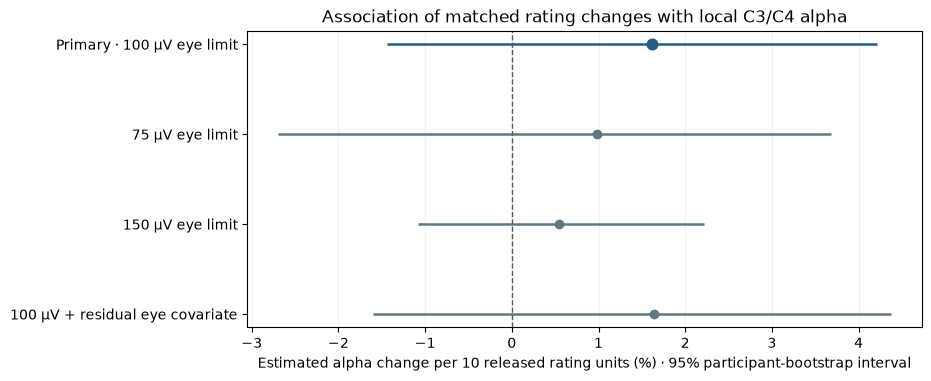

In [5]:
figure, axis = plt.subplots(figsize=(9.2, 3.7), layout="constrained")
for i, result in enumerate(result_rows):
    color = "#235c87" if i == 0 else "#607784"
    axis.hlines(i, result["Percent CI low"], result["Percent CI high"], linewidth=1.8, color=color)
    axis.scatter(result["Percent effect"], i, s=58 if i == 0 else 36, color=color, zorder=3)
axis.axvline(0, color="0.35", linestyle="--", linewidth=1)
axis.set(
    title="Association of matched rating changes with local C3/C4 alpha",
    xlabel="Estimated alpha change per 10 released rating units (%) · 95% participant-bootstrap interval",
    yticks=range(len(result_rows)), yticklabels=[row["Analysis"] for row in result_rows],
)
axis.invert_yaxis()
axis.grid(axis="x", alpha=0.16)
plt.show()

**Interpretation scope.** This is a within-task association test. The fixed sequence ties repetition to time and preceding heat. Participants can still differ in adaptation, and rating-related attention or movement may contribute. The interval describes uncertainty across contributing participants under the locked screen.

## Follow-up · Who contributed to the confirmation test?

This descriptive comparison uses the 59 confirmation recordings. A contributor had at least one repeat pair that met the locked temperature, timing, and signal criteria. Compare participants in the same 25–35-second interval of all nine heat blocks. For ratings and temperature, include valid labels from seconds that fail EEG screening. Restricting this comparison to accepted EEG would erase the information that prompted the follow-up.

Use one summary per participant. Pain ratings are in the released units, and the temperature comes from the thermode. For EEG quality, measure the share of seconds meeting the scalp rule alone, before and after the preselected channel omissions. The eye-channel rule, rating steadiness, and final acceptance are listed separately.

In [6]:
contributing = set(pairs["Participant"])
assert len(recordings) == 59 and len(contributing) == 31
assert len(set(recordings) - contributing) == 28
flow_lookup = flow.set_index("Recording")
audit_rows, level_rows = [], []
quality_masks = {}

def scalp_screen_for_audit(subject, omitted_channels):
    prefix = root / subject / "eeg" / f"{subject}_task-thermalactive"
    channel_table = pd.read_csv(f"{prefix}_channels.tsv", sep="\t")
    acquisition_channels = channel_table.loc[channel_table["type"].eq("EEG"), "name"].tolist()
    raw = mne.io.read_raw_brainvision(f"{prefix}_eeg.vhdr", preload=False, verbose="ERROR")
    samples = pd.read_csv(f"{prefix}_events.tsv", sep="\t")["sample"].to_numpy(dtype=int)
    kept = np.array([ch not in omitted_channels for ch in acquisition_channels])
    failure = []
    for sample in samples[:len(levels)]:
        block = raw.get_data(picks=acquisition_channels, start=sample + 25 * fs, stop=sample + 35 * fs)
        failure.append(eeg_failures(block.reshape(len(acquisition_channels), 10, fs)))
    all_pass = np.stack([~block.any(axis=0) for block in failure])
    after_omission = np.stack([~block[kept].any(axis=0) for block in failure])
    return all_pass, after_omission


for subject, blocks in recordings.items():
    group = "Contributed" if subject in contributing else "Did not contribute"
    info = flow_lookup.loc[subject]
    omitted = info["Omitted channels"].split(", ") if info["Omitted channels"] else []
    all_pass, after_omission = scalp_screen_for_audit(subject, omitted)

    rating = np.stack([block["Rating"] for block in blocks])
    temperature = np.stack([block["Temperature"] for block in blocks])
    valid = np.stack([block["Valid labels"] for block in blocks])
    steady = np.stack([block["Steady rating"] for block in blocks])
    eye = np.stack([block["Eye swing"] for block in blocks])
    alpha = np.stack([block["Log alpha"] for block in blocks])
    eye_accepted = np.isfinite(eye) & (eye < primary_eye_threshold)
    accepted = after_omission & eye_accepted & valid & steady & np.isfinite(alpha)
    assert np.array_equal(accepted, [block["Pass before eye screen"] & (block["Eye swing"] < primary_eye_threshold) for block in blocks])
    assert int(accepted.sum()) == info["Seconds passed"]

    # Compare repeats on matching temperature and time before scalp, eye and
    # rating-steadiness screening so both groups can be characterized.
    pre_gaps, temperature_gaps = [], []
    for level in sorted(set(levels)):
        indices = [index for index, block in enumerate(blocks) if block["Level"] == level]
        good = valid[indices]
        level_rows.append({
            "Participant": subject, "Group": group, "Level": level,
            "Median rating": float(np.median(rating[indices][good])),
            "Median temperature": float(np.median(temperature[indices][good])),
        })
        for a, b in combinations(indices, 2):
            common = valid[a] & valid[b]
            delta = np.abs(temperature[b] - temperature[a])
            temperature_gaps.append(np.median(delta[common]) if common.any() else np.nan)
            matched = common & (delta <= screen["temperature_tolerance_celsius_inclusive"] + 1e-9)
            if matched.sum() >= minimum_common:
                pre_gaps.append(abs(np.median(rating[b, matched]) - np.median(rating[a, matched])))

    audit_rows.append({
        "Participant": subject, "Group": group, "Outcome": info["Outcome"],
        "Median rating": np.median(rating[valid]),
        "Matched rating gap": np.median(pre_gaps) if pre_gaps else np.nan,
        "Median temperature": np.median(temperature[valid]),
        "Same-level temperature gap": np.nanmedian(temperature_gaps),
        "Temperature-eligible pairs": len(pre_gaps),
        "Scalp seconds pass": 100 * all_pass.mean(),
        "Scalp seconds pass after omissions": 100 * after_omission.mean(),
        "Eye seconds pass": 100 * eye_accepted.mean(),
        "Median eye swing": np.median(eye[np.isfinite(eye)]),
        "Rating-steady seconds": 100 * (valid & steady).mean(),
        "Seconds pass all rules": 100 * accepted.mean(),
        "Passing blocks": int((accepted.sum(axis=1) >= minimum_common).sum()),
    })

attrition = pd.DataFrame(audit_rows)
by_level = pd.DataFrame(level_rows)
assert set(attrition.groupby("Group").size()) == {31, 28}
assert len(by_level) == 59 * 3

## Compare participant medians and quantify uncertainty

Report participant medians in each group and the difference between them. The 95% descriptive intervals resample participants separately in the two groups. The summaries have different units and serve different purposes. EEG measures help explain how the rule selected recordings because they are part of that rule. Rating and temperature comparisons are more direct checks on whether the retained participants received or reported systematically different heat experiences.

The comparisons are exploratory. An interval spanning zero allows a range of differences, and a difference in group summaries does not identify the alpha association for recordings that lacked acceptable comparisons.

In [7]:
metrics = {
    "Median rating": "rating units",
    "Matched rating gap": "rating units",
    "Median temperature": "°C",
    "Same-level temperature gap": "°C",
    "Temperature-eligible pairs": "pairs per person",
    "Scalp seconds pass": "%",
    "Scalp seconds pass after omissions": "%",
    "Eye seconds pass": "%",
    "Median eye swing": "µV",
    "Rating-steady seconds": "%",
    "Seconds pass all rules": "%",
    "Passing blocks": "blocks per person",
}

rng = np.random.default_rng(834903)
bootstrap_n = 9999
def describe_group_difference(dataset, column):
    a = dataset.loc[dataset["Group"].eq("Contributed"), column].dropna().to_numpy()
    b = dataset.loc[dataset["Group"].eq("Did not contribute"), column].dropna().to_numpy()
    assert len(a) > 1 and len(b) > 1
    a_quartiles = np.quantile(a, [0.25, 0.5, 0.75])
    b_quartiles = np.quantile(b, [0.25, 0.5, 0.75])
    draws_a = rng.choice(a, size=(bootstrap_n, len(a)), replace=True)
    draws_b = rng.choice(b, size=(bootstrap_n, len(b)), replace=True)
    differences = np.median(draws_a, axis=1) - np.median(draws_b, axis=1)
    ci = np.quantile(differences, [0.025, 0.975])
    return {
        "Contributed n": len(a), "Did not contribute n": len(b),
        "Contributed median": a_quartiles[1], "Did not contribute median": b_quartiles[1],
        "Difference": a_quartiles[1] - b_quartiles[1], "95% CI low": ci[0], "95% CI high": ci[1],
    }

comparison = pd.DataFrame([
    {"Measure": measure, "Unit": unit, **describe_group_difference(attrition, measure)}
    for measure, unit in metrics.items()
])
display(comparison.round(2))

level_comparison = pd.DataFrame([
    {"Programmed heat": level, "Measure": measure, **describe_group_difference(group_data, measure)}
    for level, group_data in by_level.groupby("Level")
    for measure in ("Median rating", "Median temperature")
])
display(level_comparison.round(2))

outcome_summary = attrition.groupby("Outcome").agg(
    Participants=("Participant", "size"), Median_rating=("Median rating", "median"),
    Median_temperature=("Median temperature", "median"),
    Scalp_pass_pct=("Scalp seconds pass after omissions", "median"),
    Eye_pass_pct=("Eye seconds pass", "median"),
    Final_pass_pct=("Seconds pass all rules", "median"),
    Temperature_eligible_pairs=("Temperature-eligible pairs", "median"),
)
display(outcome_summary.round(2))

,Measure,Unit,Contributed n,Did not contribute n,Contributed median,Did not contribute median,Difference,95% CI low,95% CI high
0,Median rating,rating units,31,28,76.00,30.00,46.00,-4.00,64.00
1,Matched rating gap,rating units,31,28,30.00,19.00,11.00,-2.00,23.00
2,Median temperature,°C,31,28,44.64,44.91,-0.27,-1.25,1.46
3,Same-level temperature gap,°C,31,28,0.02,0.02,0.00,0.00,0.00
4,Temperature-eligible pairs,pairs per person,31,28,9.00,9.00,0.00,0.00,0.00
5,Scalp seconds pass,%,31,28,72.22,23.33,48.89,30.56,68.89
6,Scalp seconds pass after omissions,%,31,28,86.67,42.22,44.44,33.33,58.33
7,Eye seconds pass,%,31,28,75.56,27.78,47.78,34.44,57.78
8,Median eye swing,µV,31,28,31.66,225.52,-193.86,-237.20,-122.20
9,Rating-steady seconds,%,31,28,97.78,94.44,3.33,-1.11,5.56


,Programmed heat,Measure,Contributed n,Did not contribute n,Contributed median,Did not contribute median,Difference,95% CI low,95% CI high
0,50,Median rating,31,28,16.00,8.00,8.00,-8.00,38.00
1,50,Median temperature,31,28,41.64,42.47,-0.83,-1.74,1.30
2,100,Median rating,31,28,50.00,26.50,23.50,-10.00,47.52
3,100,Median temperature,31,28,44.64,44.91,-0.27,-1.24,1.43
4,150,Median rating,31,28,144.00,136.00,8.00,-10.00,29.00
5,150,Median temperature,31,28,47.17,46.89,0.28,-0.80,1.32


,Participants,Median_rating,Median_temperature,Scalp_pass_pct,Eye_pass_pct,Final_pass_pct,Temperature_eligible_pairs
Outcome,,,,,,,
Contributed to test,31,76.0,44.64,86.67,75.56,66.67,9.0
No block with five passing seconds,15,28.0,45.00,27.78,17.78,8.89,9.0
"Passing block, no matched pair",13,60.0,44.28,44.44,41.11,31.11,9.0


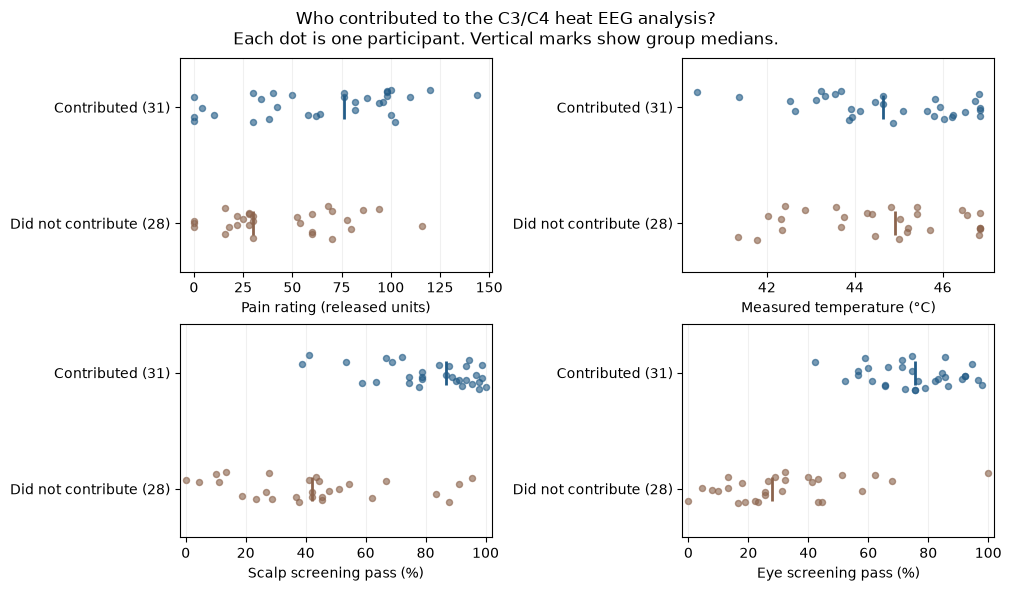

In [8]:
panel_specs = [
    ("Median rating", "Pain rating (released units)"),
    ("Median temperature", "Measured temperature (°C)"),
    ("Scalp seconds pass after omissions", "Scalp screening pass (%)"),
    ("Eye seconds pass", "Eye screening pass (%)"),
]
figure, axes = plt.subplots(2, 2, figsize=(10, 5.8), layout="constrained")
group_style = [
    ("Contributed", "Contributed (31)", "#235c87"),
    ("Did not contribute", "Did not contribute (28)", "#8c644d"),
]
plot_rng = np.random.default_rng(914)
for axis, (column, xlabel) in zip(axes.flat, panel_specs):
    for index, (group, label, color) in enumerate(group_style):
        values = attrition.loc[attrition["Group"].eq(group), column]
        jitter = plot_rng.uniform(-0.15, 0.15, len(values))
        axis.scatter(values, index + jitter, color=color, alpha=0.62, s=19)
        axis.scatter(values.median(), index, marker="|", color=color, s=300, linewidth=2)
    axis.set(xlabel=xlabel, yticks=range(2), yticklabels=[style[1] for style in group_style], ylim=(1.42, -0.42))
    if column.endswith("pass") or column.endswith("omissions"):
        axis.set_xlim(-2, 102)
    axis.grid(axis="x", alpha=0.18)
figure.suptitle("Who contributed to the C3/C4 heat EEG analysis?\nEach dot is one participant. Vertical marks show group medians.")
plt.show()

### What the comparison means for the alpha result

The largest group differences were in the signals used for screening. The median contributor passed the scalp rule in 86.7% of seconds after channel omissions, compared with 42.2% for a noncontributor. The corresponding eye-screen pass rates were 75.6% and 27.8%. All 59 people had nine eligible temperature-matched repeat pairs before artifact screening. The rating-steadiness rates were closer, at 97.8% and 94.4%.

Participant median ratings were 76 and 30, respectively. The difference between those group medians was 46 released units, with a 95% descriptive participant-bootstrap interval of −4 to +64. At each programmed level, contributors also had a higher point estimate for median rating, with uncertainty spanning zero. Their same-level matched rating gaps tended to be larger (30 versus 19 units, difference interval −2 to +23). Measured temperatures were 44.64°C and 44.91°C, with a difference interval of −1.25°C to +1.46°C.

The primary estimate remains +1.62% alpha power per ten rating units, with a 95% interval from −1.44% to +4.21%. Losing eligible participants reduces information and narrows the population represented. Since ratings and recording quality can differ by retention, the full 59-person association could differ from the screened association in either direction. The prespecified 150 µV eye-screen sensitivity included 37 participants and also had an interval spanning zero.

## Follow-up · Recover seconds using eye-channel regression

This is a sensitivity analysis of the already examined confirmation cohort. We use a fixed, low-frequency two-lead EOG regression rule before fitting the corrected alpha model. The locked test keeps its original data and results.

1. Fit a per-recording regression from the slow **1–10 Hz** eye traces to the slow scalp traces. Use seconds **15–25** after block markers with **100–500 µV** eye swing, at least five seconds across at least three blocks. Remove each second's mean when fitting. Use a small ridge penalty on the standardized eye predictors.
2. Validate on separate seconds **10–14**, with a one-second gap before calibration. Require at least three high-eye seconds from at least two blocks. The fitted correction must reduce the median eye-aligned frontal EEG RMS by at least **25%**. The median eye-aligned local C3/C4 RMS must remain at or below **5 µV** and increase by at most **1 µV**.
3. In the **25–35-second** analysis window, carry forward the original signal and power in seconds that already passed. Consider rescuing rejected seconds with a raw eye swing from 100 to 500 µV only if the recording passed validation. Reapply the scalp amplitude screen using the same omitted channels, keep the original steady-rating and label rules, and require the corrected residual eye-aligned amplitude to be at most **15 µV at the frontal channels** and **5 µV at local C3/C4**. Require a reduction in frontal leakage and no increase over 1 µV locally. Keep the same temperature matching and minimum number of shared seconds.
4. Rerun the same alpha model and participant bootstrap on the expanded set, then run it on the corrected comparisons from the original 31 participants to help separate added data from added people.

Eye-aligned RMS is the root-mean-square amplitude of the slow EEG waveform projected onto the two slow eye waveforms within a second. The frontal summary is the median across remaining Fp/AF sites. The central summary is the larger of the two locally referenced values. These are conservative pilot gates. EOG regression can also remove some neural activity shared with the eye traces. The [MNE regression tutorial](https://mne.tools/stable/auto_tutorials/preprocessing/35_artifact_correction_regression.html) describes that limitation.

In [9]:
regression_fit_range = range(15, 25)
regression_validation_range = range(10, 14)
analysis_range = range(25, 35)
regression_min_eye = 100.0
regression_max_eye = 500.0
ridge = 0.01
front_limit = 15.0
central_limit = 5.0

def second_slice(seconds):
    return slice(seconds.start - 7, seconds.stop - 7)

def demean(seconds):
    return seconds - seconds.mean(axis=-1, keepdims=True)

def projected_rms(eeg_seconds, eye_seconds):
    # Per-second orthonormal basis for the eye traces, with a rank check.
    eye = demean(eye_seconds)
    u, singular, _ = np.linalg.svd(eye.T, full_matrices=False)
    use = singular > max(1e-12, singular[0] * 1e-7)
    amplitudes = demean(eeg_seconds) @ u[:, use]
    return np.linalg.norm(amplitudes, axis=1) * (1e6 / np.sqrt(eeg_seconds.shape[-1]))

def read_eye_screening_data(subject):
    prefix = root / subject / "eeg" / f"{subject}_task-thermalactive"
    channel_table = pd.read_csv(f"{prefix}_channels.tsv", sep="\t")
    eeg = channel_table.loc[channel_table["type"].eq("EEG"), "name"].tolist()
    raw = mne.io.read_raw_brainvision(f"{prefix}_eeg.vhdr", eog=eye_names, preload=False, verbose="ERROR")
    samples = pd.read_csv(f"{prefix}_events.tsv", sep="\t")["sample"].to_numpy(dtype=int)
    raw_blocks, slow_blocks, eye_blocks = [], [], []
    for sample in samples[:len(levels)]:
        # The buffer precedes the first validation second and follows the last
        # analysis second. Filtering is confined to each block.
        raw_data = raw.get_data(picks=eeg + eye_names, start=sample + 7 * fs, stop=sample + 38 * fs)
        scalp, eye = raw_data[:len(eeg)], raw_data[len(eeg):]
        slow = signal.sosfiltfilt(eye_filter, raw_data, axis=1)
        raw_blocks.append(scalp.reshape(len(eeg), 31, fs))
        slow_blocks.append(slow[:len(eeg)].reshape(len(eeg), 31, fs))
        eye_blocks.append(slow[len(eeg):].reshape(len(eye_names), 31, fs))
    return eeg, np.stack(raw_blocks), np.stack(slow_blocks), np.stack(eye_blocks)

def local_contrast(channel_data, eeg):
    return np.stack([
        channel_data[eeg.index(center)] - channel_data[[eeg.index(ch) for ch in adjacent]].mean(axis=0)
        for center, adjacent in neighbors.items()
    ])

def local_alpha(channel_data, eeg):
    local = local_contrast(channel_data, eeg)
    frequency, psd = signal.periodogram(local, fs=fs, window="hann", detrend="constant", axis=-1)
    low, high = plan["alpha"]["frequency_bins_hz_inclusive"]
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.log(psd[:, (frequency >= low) & (frequency <= high)].sum(axis=1)).mean()

def slow_eye_metrics(eeg_second, eye_second, eeg, frontal):
    values = projected_rms(np.vstack([eeg_second[frontal], local_contrast(eeg_second, eeg)]), eye_second)
    return np.array([np.median(values[:-2]), values[-2:].max()])

def train_eye_regression(slow_blocks, eye_blocks, eye_swings):
    train_slice = second_slice(regression_fit_range)
    eye_selection = eye_swings[:, train_slice]
    train_mask = np.isfinite(eye_selection) & (eye_selection >= regression_min_eye) & (eye_selection <= regression_max_eye)
    count = int(train_mask.sum())
    if count < 5 or np.count_nonzero(train_mask.any(axis=1)) < 3:
        return None, count
    x = demean(eye_blocks[:, :, train_slice, :].transpose(0, 2, 1, 3)[train_mask])
    y = demean(slow_blocks[:, :, train_slice, :].transpose(0, 2, 1, 3)[train_mask])
    x = x.transpose(0, 2, 1).reshape(-1, len(eye_names))
    y = y.transpose(0, 2, 1).reshape(len(x), -1)
    scale = x.std(axis=0)
    if not (np.isfinite(scale).all() and np.all(scale > 0) and np.isfinite(y).all()):
        return None, count
    normalized = x / scale
    gram = normalized.T @ normalized / len(x)
    coeffs = np.linalg.solve(gram + ridge * np.eye(len(eye_names)), normalized.T @ y / len(x))
    return coeffs / scale[:, None], count

def validate_eye_regression(coeffs, slow_blocks, eye_blocks, eye_swings, eeg, frontal):
    validation = second_slice(regression_validation_range)
    raw_scores, corrected_scores = [], []
    contributing_blocks = 0
    for block in range(len(slow_blocks)):
        assessed = False
        for index in range(validation.start, validation.stop):
            if not regression_min_eye <= eye_swings[block, index] <= regression_max_eye:
                continue
            slow, eye = slow_blocks[block, :, index], eye_blocks[block, :, index]
            if not np.isfinite(slow).all() or not np.isfinite(eye).all():
                continue
            predicted = coeffs.T @ eye
            raw_scores.append(slow_eye_metrics(slow, eye, eeg, frontal))
            corrected_scores.append(slow_eye_metrics(slow - predicted, eye, eeg, frontal))
            assessed = True
        contributing_blocks += int(assessed)
    if len(raw_scores) < 3 or contributing_blocks < 2:
        return None
    before, after = np.median(raw_scores, axis=0), np.median(corrected_scores, axis=0)
    passed = before[0] > 0 and after[0] <= 0.75 * before[0] and after[1] <= min(central_limit, before[1] + 1)
    return {"Validation seconds": len(raw_scores), "Frontal RMS before": before[0], "Frontal RMS after": after[0],
            "Local RMS before": before[1], "Local RMS after": after[1], "Validated": bool(passed)}

In [10]:
correction_recordings, eye_validation_rows = {}, []
recovered_seconds_by_person = {}
alpha_check_rows = []

for subject, original_blocks in recordings.items():
    eeg, raw_blocks, slow_blocks, eye_blocks = read_eye_screening_data(subject)
    eye_swings = np.ptp(eye_blocks, axis=-1).max(axis=1) * 1e6
    omissions = flow_lookup.loc[subject, "Omitted channels"]
    excluded_channels = omissions.split(", ") if omissions else []
    keep = np.array([name not in excluded_channels for name in eeg])
    frontal = [i for i, ch in enumerate(eeg) if keep[i] and ch.startswith(("Fp", "AF"))]
    assert frontal

    coeffs, calibration_seconds = train_eye_regression(slow_blocks, eye_blocks, eye_swings)
    assessment = validate_eye_regression(coeffs, slow_blocks, eye_blocks, eye_swings, eeg, frontal) if coeffs is not None else None
    validated = assessment is not None and assessment["Validated"]
    validation_row = {"Participant": subject, "Calibration seconds": calibration_seconds, "Validated": validated}
    if assessment:
        validation_row.update(assessment)
    eye_validation_rows.append(validation_row)

    new_blocks = []
    restored = 0
    for block_index, original in enumerate(original_blocks):
        primary_mask = original["Pass before eye screen"] & (original["Eye swing"] < primary_eye_threshold)
        accepted = primary_mask.copy()
        alpha = original["Log alpha"].copy()
        if validated:
            for j, relative_second in enumerate(analysis_range):
                index = relative_second - 7
                scalp, slow = raw_blocks[block_index, :, index], slow_blocks[block_index, :, index]
                eye = eye_blocks[block_index, :, index]
                predicted = coeffs.T @ eye
                if primary_mask[j]:
                    # Quantify potential power distortion if we corrected a
                    # clean second, but carry its original alpha into the model.
                    candidate_alpha = local_alpha(scalp - predicted, eeg)
                    if np.isfinite(candidate_alpha):
                        alpha_check_rows.append({
                            "Participant": subject,
                            "Absolute alpha change %": abs(100 * np.expm1(candidate_alpha - alpha[j])),
                        })
                    continue
                if not (
                    original["Valid labels"][j] and original["Steady rating"][j]
                    and regression_min_eye <= original["Eye swing"][j] <= regression_max_eye
                    and regression_min_eye <= eye_swings[block_index, index] <= regression_max_eye
                ):
                    continue
                corrected = scalp - predicted
                if eeg_failures(corrected[keep]).any():
                    continue
                before = slow_eye_metrics(slow, eye, eeg, frontal)
                after = slow_eye_metrics(slow - predicted, eye, eeg, frontal)
                if after[0] >= before[0] or after[0] > front_limit or after[1] > min(central_limit, before[1] + 1):
                    continue
                candidate_alpha = local_alpha(corrected, eeg)
                if np.isfinite(candidate_alpha):
                    accepted[j] = True
                    alpha[j] = candidate_alpha
                    restored += 1
        assert np.all(accepted[primary_mask]) and np.array_equal(alpha[primary_mask], original["Log alpha"][primary_mask])
        new_blocks.append({**original, "Pass before eye screen": accepted, "Log alpha": alpha})
    correction_recordings[subject] = new_blocks
    recovered_seconds_by_person[subject] = restored

eye_validation = pd.DataFrame(eye_validation_rows)
validation_passed = eye_validation.loc[eye_validation["Validated"]]
alpha_change_check = pd.DataFrame(alpha_check_rows)
alpha_person_median = alpha_change_check.groupby("Participant")["Absolute alpha change %"].median()
print(f"Regression passed validation in {len(validation_passed)}/{len(eye_validation)} recordings.")
if len(validation_passed):
    print(f"Median frontal eye-aligned RMS across validated recordings: "
          f"{validation_passed['Frontal RMS before'].median():.1f} to {validation_passed['Frontal RMS after'].median():.1f} µV.")
    print(f"Median local eye-aligned RMS across validated recordings: "
          f"{validation_passed['Local RMS before'].median():.1f} to {validation_passed['Local RMS after'].median():.1f} µV.")
print(f"Recovered {sum(recovered_seconds_by_person.values())} seconds in "
      f"{sum(value > 0 for value in recovered_seconds_by_person.values())} recordings.")
print(f"Typical absolute change if correction were applied to already-passing seconds: "
      f"{alpha_person_median.median():.2f}% alpha power (median of participant medians).")

Regression passed validation in 56/59 recordings.
Median frontal eye-aligned RMS across validated recordings: 12.2 to 2.0 µV.
Median local eye-aligned RMS across validated recordings: 0.4 to 0.3 µV.
Recovered 1232 seconds in 54 recordings.
Typical absolute change if correction were applied to already-passing seconds: 0.24% alpha power (median of participant medians).


## Repeat the alpha model with the recovered data

The combined eligibility mask preserves all locked seconds and adds only corrected seconds that meet the preceding rules. The pairing function therefore uses that mask in place of applying the raw-eye limit a second time. Reuse the same rating coefficient, covariates, participant weights, and participant-bootstrap interval for each sensitivity estimate.

In [11]:
corrected_pairs, corrected_retention = build_pairs(correction_recordings, np.inf)
locked_keys = ["Participant", "Level", "Earlier block", "Later block"]
index_locked = pd.MultiIndex.from_frame(pairs[locked_keys])
index_corrected = pd.MultiIndex.from_frame(corrected_pairs[locked_keys])
assert index_locked.isin(index_corrected).all()
corrected_people = set(corrected_pairs["Participant"])
new_contributors = corrected_people - contributing
assert len(new_contributors) == len(corrected_people) - len(contributing)
assert corrected_retention["Seconds passed"].sum() == flow["Seconds passed"].sum() + sum(recovered_seconds_by_person.values())
recovered_seconds_in_excluded = sum(n for subject, n in recovered_seconds_by_person.items() if subject not in contributing)

comparison_results = pd.DataFrame([
    {"Analysis": "Locked result", **primary_result},
    {"Analysis": "With eye correction", **fit_association(corrected_pairs)},
    {"Analysis": "With eye correction, original participants",
     **fit_association(corrected_pairs.loc[corrected_pairs["Participant"].isin(contributing)])},
])
print(f"Originally excluded recordings recovered: {len(new_contributors)} of {len(recordings) - len(contributing)}.")
print(f"Seconds recovered among originally excluded recordings: {recovered_seconds_in_excluded}.")
print(f"Usable matched pairs: {len(pairs)} to {len(corrected_pairs)}.")
display(comparison_results[["Analysis", "Participants", "Pairs", "Percent effect", "Percent CI low",
                           "Percent CI high", "Two-sided p", "Valid bootstrap draws"]].round(4))

Originally excluded recordings recovered: 19 of 28.
Seconds recovered among originally excluded recordings: 763.
Usable matched pairs: 140 to 312.


,Analysis,Participants,Pairs,Percent effect,Percent CI low,Percent CI high,Two-sided p,Valid bootstrap draws
0,Primary · 100 µV eye limit,31,140,1.6167,-1.4440,4.2133,0.2624,9999
1,With eye correction,50,312,0.1310,-1.1454,1.3541,0.7750,9999
2,"With eye correction, original participants",31,227,-0.5691,-1.9493,0.9670,0.4702,9999


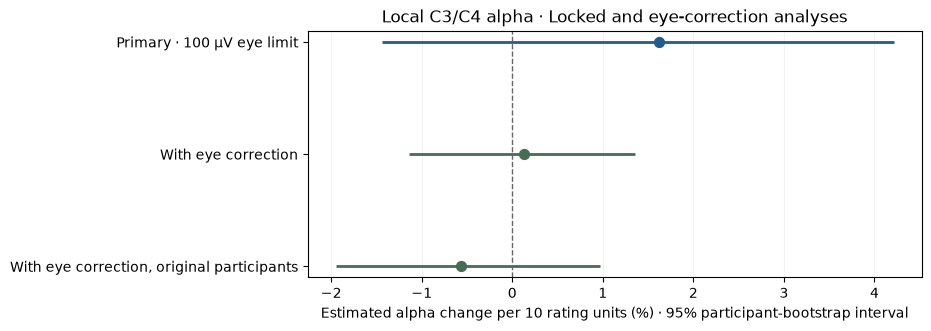

In [12]:
fig, axis = plt.subplots(figsize=(9.2, 3.2), layout="constrained")
for row_index, row in comparison_results.iterrows():
    color = "#235c87" if row_index == 0 else "#486b55"
    axis.hlines(row_index, row["Percent CI low"], row["Percent CI high"], color=color, linewidth=2)
    axis.scatter(row["Percent effect"], row_index, color=color, s=50, zorder=3)
axis.axvline(0, color="0.4", linewidth=1, linestyle="--")
axis.set(
    yticks=range(len(comparison_results)), yticklabels=comparison_results["Analysis"],
    xlabel="Estimated alpha change per 10 rating units (%) · 95% participant-bootstrap interval",
    title="Local C3/C4 alpha · Locked and eye-correction analyses",
)
axis.invert_yaxis()
axis.grid(axis="x", alpha=0.16)
plt.show()

### What the corrected sensitivity check showed

The regression passed validation in 56 of 59 recordings. Across those recordings, median frontal eye-aligned RMS fell from 12.2 to 2.0 µV in independent validation windows, while the local C3/C4 median changed from 0.35 to 0.33 µV. The rescue rules recovered 1,232 seconds overall, including 763 in participants who were originally excluded. Nineteen of the 28 originally excluded people gained a matched repeat pair.

The same model estimated +0.13% alpha power per ten rating units in the expanded set (50 people, 312 comparisons, 95% participant-bootstrap CI −1.15% to +1.35%, two-sided p = 0.775). Using the corrected comparisons in the original 31 participants gave −0.57% (95% CI −1.95% to +0.97%). The shift toward zero therefore also appeared when the people stayed fixed and the eligible windows changed.

Regression addresses the slow EEG activity aligned with the eye leads. Shared brain and eye-trace variance can be attenuated as well. The accepted original seconds kept their original alpha power, and the 19 newly included people improve coverage under this specific correction. This is a post hoc sensitivity check in the same cohort. The locked +1.62% estimate and its confidence interval remain the primary confirmation result.